# 03 – Autoencoder (corrected)

Replaces `03_autoencoder_model.ipynb`.

**What changed**
1. **Seeds fixed** for Python, NumPy and TensorFlow (with deterministic ops where available). The thesis run was unseeded, which is why its figures, text and notebook disagree (for example ROC-AUC 0.9382 in the thesis figure, 0.9121 in the notebook, "≈ 0.94" in the text).
2. **Architecture matches the thesis:** 64 → 32 → **16 (latent)** → 32 → 64. The original notebook had no 16-unit layer.
3. **Scaler fitted on training normal traffic only.**
4. **Alert thresholds come from held-out validation normal traffic**, not from the test set. The original computed the percentile on the test set's normal rows, which uses test labels to set the threshold.
5. **Early stopping** on validation loss, and every reported number is printed by the code that produces it.

In [1]:
import os, random, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
import tensorflow as tf
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("Deterministic ops not available:", e)

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)
print("TensorFlow", tf.__version__)

I0000 00:00:1793604992.092137    1127 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793604993.468074    1127 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


In [2]:
df = pd.read_csv("features_conn.csv")
split = df.pop("split")
capture = df.pop("capture")
y = df.pop("label").astype(int)
feature_names = df.columns.tolist()
X = df.values.astype("float32")

tr, va, te = (split == "train").values, (split == "val_normal").values, (split == "test").values
print("train:", tr.sum(), " val (normal only):", va.sum(), " test:", te.sum())
print("test class balance:", y[te].value_counts().to_dict())

train: 101467  val (normal only): 3105  test: 26143
test class balance: {1: 22262, 0: 3881}


In [3]:
X_train_normal = X[tr & (y.values == 0)]
X_val_normal = X[va]
X_test, y_test = X[te], y[te].values

scaler = StandardScaler().fit(X_train_normal)
Xtn, Xvn, Xte = (scaler.transform(a) for a in (X_train_normal, X_val_normal, X_test))
print("Autoencoder training rows (normal only):", len(Xtn))

Autoencoder training rows (normal only): 12417


In [4]:
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

d = Xtn.shape[1]
inp = Input(shape=(d,))
h = Dense(64, activation="relu")(inp)
h = Dense(32, activation="relu")(h)
z = Dense(16, activation="relu", name="latent")(h)
h = Dense(32, activation="relu")(z)
h = Dense(64, activation="relu")(h)
out = Dense(d, activation="linear")(h)
autoencoder = Model(inp, out)
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

history = autoencoder.fit(
    Xtn, Xtn, epochs=50, batch_size=256, shuffle=True,
    validation_data=(Xvn, Xvn),
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=0)
print("Epochs run:", len(history.history["loss"]),
      " best val loss:", round(min(history.history["val_loss"]), 5))

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 50)             │         3,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,778 (46.01 KB)

 Trainable params: 11,778 (46.01 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 45  best val loss: 0.00823


In [5]:
def recon_error(A):
    return np.mean((A - autoencoder.predict(A, verbose=0)) ** 2, axis=1)

val_err = recon_error(Xvn)
test_err = recon_error(Xte)

auc = roc_auc_score(y_test, test_err)
ap = average_precision_score(y_test, test_err)
print(f"ROC-AUC: {auc:.4f}   PR-AUC (average precision): {ap:.4f}")

ROC-AUC: 0.9827   PR-AUC (average precision): 0.9968


In [6]:
rows, cms = [], {}
for p in [95, 90, 85, 80]:
    thr = np.percentile(val_err, p)
    pred = (test_err > thr).astype(int)
    cms[p] = confusion_matrix(y_test, pred)
    rows.append({"model": f"Autoencoder ({p}th pct)", "threshold": thr,
                 "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred), "false_positive_rate": cms[p][0, 1] / cms[p][0].sum()})
    print(f"\n{p}th percentile threshold = {thr:.5f}\n{cms[p]}")

ae_table = pd.DataFrame(rows)
ae_table.round(3)


95th percentile threshold = 0.02742
[[ 3675   206]
 [ 2552 19710]]

90th percentile threshold = 0.01140
[[ 3456   425]
 [  459 21803]]

85th percentile threshold = 0.00665
[[ 3280   601]
 [  374 21888]]

80th percentile threshold = 0.00511
[[ 3092   789]
 [  371 21891]]


,model,threshold,precision,recall,f1,false_positive_rate
0,Autoencoder (95th pct),0.027,0.990,0.885,0.935,0.053
1,Autoencoder (90th pct),0.011,0.981,0.979,0.980,0.110
2,Autoencoder (85th pct),0.007,0.973,0.983,0.978,0.155
3,Autoencoder (80th pct),0.005,0.965,0.983,0.974,0.203


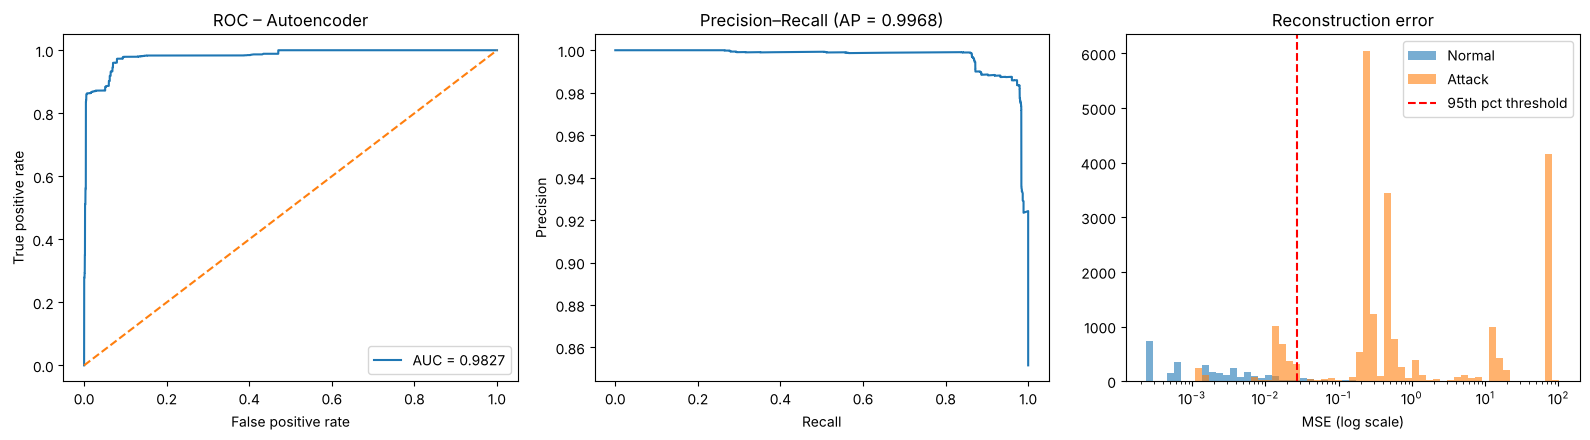

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(y_test, test_err)
ax[0].plot(fpr, tpr, label=f"AUC = {auc:.4f}"); ax[0].plot([0, 1], [0, 1], "--")
ax[0].set(title="ROC – Autoencoder", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend()

pr, rc, _ = precision_recall_curve(y_test, test_err)
ax[1].plot(rc, pr); ax[1].set(title=f"Precision–Recall (AP = {ap:.4f})", xlabel="Recall", ylabel="Precision")

bins = np.logspace(np.log10(test_err.min() + 1e-6), np.log10(test_err.max()), 60)
ax[2].hist(test_err[y_test == 0], bins=bins, alpha=0.6, label="Normal")
ax[2].hist(test_err[y_test == 1], bins=bins, alpha=0.6, label="Attack")
ax[2].axvline(np.percentile(val_err, 95), color="red", ls="--", label="95th pct threshold")
ax[2].set_xscale("log"); ax[2].set(title="Reconstruction error", xlabel="MSE (log scale)"); ax[2].legend()
plt.tight_layout(); plt.savefig("figures/ae_roc_pr_error.png", dpi=150); plt.show()

Per-feature reconstruction error (attack minus normal) shows which features the autoencoder finds hardest to reconstruct for attack traffic. These rows are aligned with the test set, unlike the original feature analysis.

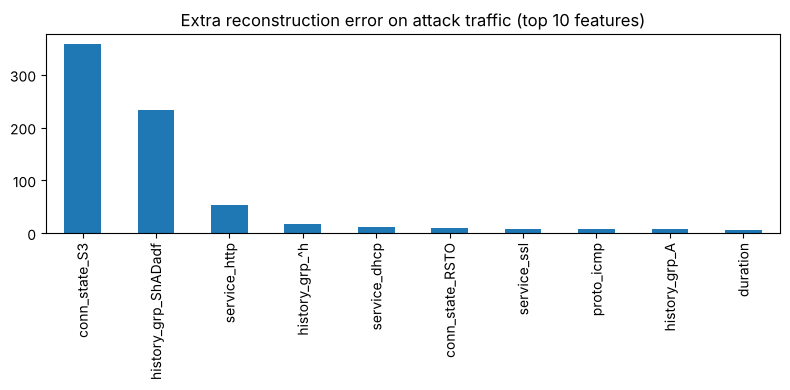

conn_state_S3          358.428986
history_grp_ShADadf    232.460007
service_http            52.724998
history_grp_^h          16.872999
service_dhcp            12.457000
conn_state_RSTO          9.170000
service_ssl              8.180000
proto_icmp               7.961000
history_grp_A            7.147000
duration                 6.835000
dtype: float32

In [8]:
per_feat = (Xte - autoencoder.predict(Xte, verbose=0)) ** 2
contrib = pd.Series(per_feat[y_test == 1].mean(0) - per_feat[y_test == 0].mean(0),
                    index=feature_names).sort_values(ascending=False)
contrib.head(10).plot(kind="bar", figsize=(8, 4), title="Extra reconstruction error on attack traffic (top 10 features)")
plt.tight_layout(); plt.savefig("figures/ae_feature_contribution.png", dpi=150); plt.show()
contrib.head(10).round(3)

In [9]:
pd.DataFrame({"row_id": np.where(te)[0], "label": y_test, "ae_error": test_err}).to_csv("results/ae_test_scores.csv", index=False)
contrib.to_csv("results/ae_feature_contribution.csv", header=["extra_error"])
ae_table.to_csv("results/ae_thresholds.csv", index=False)
json.dump({"roc_auc": auc, "pr_auc": ap, "val_err_percentiles": {p: float(np.percentile(val_err, p)) for p in [80, 85, 90, 95]}},
          open("results/ae_summary.json", "w"), indent=2)
print("Saved results/ae_*")

Saved results/ae_*
